In [ ]:
#Cell 1: Environment Setup
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "einops", "scikit-learn", "matplotlib",
                "seaborn", "opencv-python-headless", "scipy"], check=False)
print("Environment ready")

!pip install -q streamlit pyngrok

Environment ready
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 37.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 32.8 MB/s eta 0:00:00


In [ ]:
#Cell 2: Mount Drive & Set Paths
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

ROOT        = Path("/content/drive/MyDrive/Dataset")
UCSD_ROOT   = ROOT / "ucsd_ped2"
SHTECH_ROOT = ROOT / "shanghaitech"
SAVE_DIR    = ROOT / "checkpoints"
SAVE_DIR.mkdir(exist_ok=True)

print(f"UCSD  root : {UCSD_ROOT}")
print(f"SHTech root: {SHTECH_ROOT}")
print(f"Checkpoints: {SAVE_DIR}")

Mounted at /content/drive
UCSD  root : /content/drive/MyDrive/Dataset/ucsd_ped2
SHTech root: /content/drive/MyDrive/Dataset/shanghaitech
Checkpoints: /content/drive/MyDrive/Dataset/checkpoints


In [ ]:
#Cell 3: Constants
import torch

CLIP_LEN   = 16
IMG_SIZE   = 128
STRIDE     = 4
BATCH_SIZE = 8
DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device: {DEVICE}")
if DEVICE.type == 'cuda':
    print(f"GPU   : {torch.cuda.get_device_name(0)}")

Device: cuda
GPU   : Tesla T4


In [ ]:
#Cell 4: UCSD Ped2 Dataset Class (with temporal augmentation)
import torch
from torch.utils.data import Dataset
import cv2
import numpy as np
from pathlib import Path

class UCSDPed2Dataset(Dataset):
    """
    Loads 16-frame sliding window clips from UCSD Ped2.
    UPGRADE: Added temporal jitter + spatial augmentation for training.
    """
    def __init__(self, root, clip_len=16, stride=4,
                 img_size=128, mode='train', augment=True):
        self.clip_len = clip_len
        self.img_size = img_size
        self.mode     = mode
        self.augment  = augment and (mode == 'train')

        subfolder = 'Train' if mode == 'train' else 'Test'
        root_path = Path(root) / subfolder

        folders = sorted([f for f in root_path.iterdir()
                          if f.is_dir() and '_gt' not in f.name])

        self.clips = []
        for folder in folders:
            frames = sorted(list(folder.glob('*.tif')) +
                            list(folder.glob('*.png')))
            for start in range(0, len(frames) - clip_len + 1, stride):
                self.clips.append(frames[start:start + clip_len])

        print(f"UCSDPed2 [{mode}]: {len(folders)} scenes, {len(self.clips)} clips")

    def _load(self, path):
        img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (self.img_size, self.img_size))
        return img.astype(np.float32) / 255.0

    def __len__(self):
        return len(self.clips)

    def __getitem__(self, idx):
        paths = self.clips[idx]
        frames = np.stack([self._load(p) for p in paths], axis=0)  # (T, H, W)

        if self.augment:
            # Random horizontal flip
            if np.random.rand() > 0.5:
                frames = frames[:, :, ::-1].copy()
            # Random brightness jitter
            frames = np.clip(frames + np.random.uniform(-0.05, 0.05), 0, 1)

        # Normalize to [-1, 1]
        frames = (frames - 0.5) / 0.5
        return torch.tensor(frames, dtype=torch.float32).unsqueeze(0)  # (1,T,H,W)


ucsd_train = UCSDPed2Dataset(UCSD_ROOT, clip_len=CLIP_LEN,
                              stride=STRIDE, img_size=IMG_SIZE,
                              mode='train', augment=True)
print(f"Training clips: {len(ucsd_train)}")

UCSDPed2 [train]: 16 scenes, 586 clips
Training clips: 586


In [ ]:
#Cell 5: ShanghaiTech Dataset Class
class ShanghaiTechDataset(Dataset):
    """
    Loads 16-frame sliding window clips from ShanghaiTech scenes 01-04.
    """
    def __init__(self, root, clip_len=16, stride=4, img_size=128, augment=True):
        self.clip_len = clip_len
        self.img_size = img_size
        self.augment  = augment

        root_path = Path(root)
        train_folders = sorted([f for f in root_path.iterdir()
                                 if f.is_dir() and
                                 f.name[:2] in ['01','02','03','04']])

        self.clips = []
        for folder in train_folders:
            frame_dir = folder / 'frames'
            if not frame_dir.exists():
                continue
            frames = sorted(list(frame_dir.glob('*.jpg')) +
                            list(frame_dir.glob('*.png')))
            for start in range(0, len(frames) - clip_len + 1, stride):
                self.clips.append(frames[start:start + clip_len])

        print(f"ShanghaiTech: {len(train_folders)} scenes, {len(self.clips)} clips")

    def _load(self, path):
        img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (self.img_size, self.img_size))
        return img.astype(np.float32) / 255.0

    def __len__(self):
        return len(self.clips)

    def __getitem__(self, idx):
        paths = self.clips[idx]
        frames = np.stack([self._load(p) for p in paths], axis=0)

        if self.augment:
            if np.random.rand() > 0.5:
                frames = frames[:, :, ::-1].copy()
            frames = np.clip(frames + np.random.uniform(-0.05, 0.05), 0, 1)

        frames = (frames - 0.5) / 0.5
        return torch.tensor(frames, dtype=torch.float32).unsqueeze(0)

Batches per epoch: 73


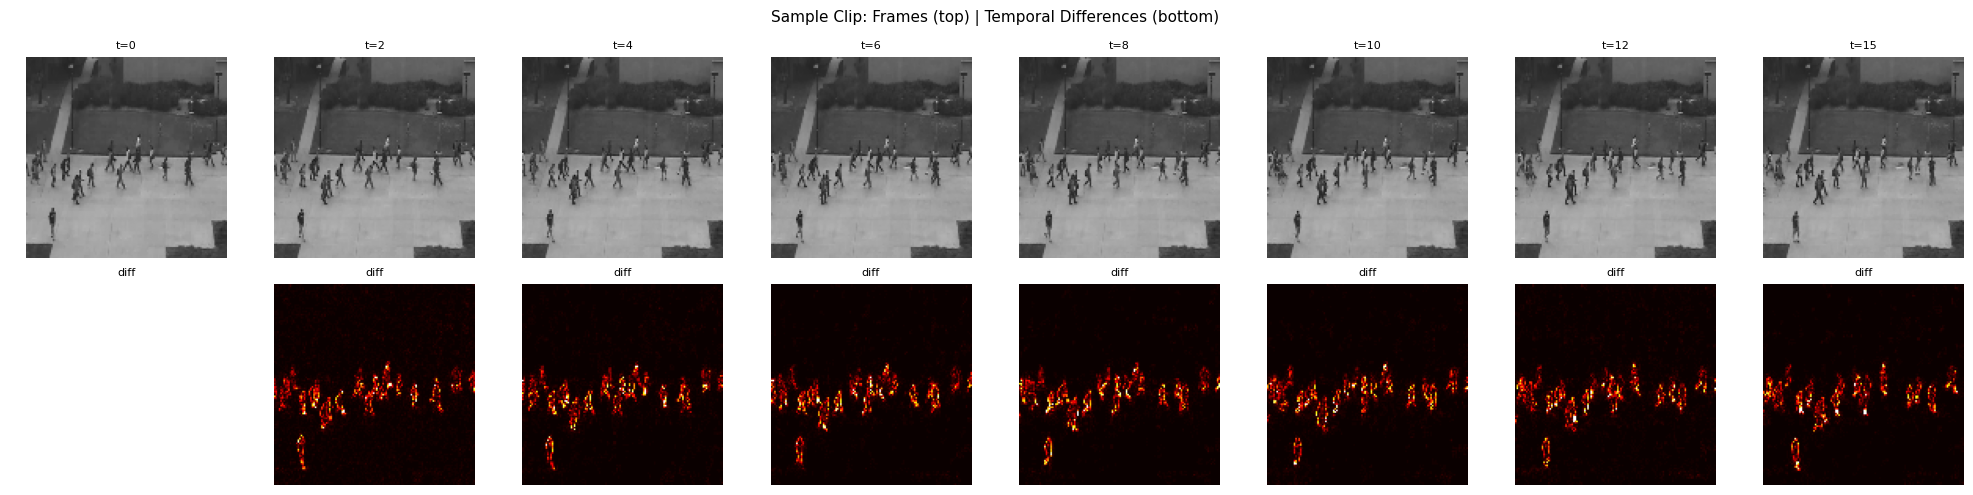

In [ ]:
#Cell 6: DataLoaders + Visualisation
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

ucsd_loader = DataLoader(ucsd_train, batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=2, pin_memory=True,
                          drop_last=True)

print(f"Batches per epoch: {len(ucsd_loader)}")

# Visualise a sample clip
sample = ucsd_train[0]  # (1, 16, 128, 128)
fig, axes = plt.subplots(2, 8, figsize=(20, 5))
indices = np.linspace(0, 15, 8, dtype=int)
for i, idx in enumerate(indices):
    frame = sample[0, idx].numpy() * 0.5 + 0.5
    axes[0, i].imshow(frame, cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(f't={idx}', fontsize=8)
    axes[0, i].axis('off')
    # Show frame difference (temporal gradient)
    if idx > 0:
        prev = sample[0, idx-1].numpy() * 0.5 + 0.5
        diff = np.abs(frame - prev)
        axes[1, i].imshow(diff, cmap='hot', vmin=0, vmax=0.3)
    axes[1, i].set_title('diff', fontsize=8)
    axes[1, i].axis('off')
fig.suptitle('Sample Clip: Frames (top) | Temporal Differences (bottom)', fontsize=11)
plt.tight_layout()
plt.show()

In [ ]:
#Cell 7: Original 3D ConvAE (matches saved checkpoints)
import torch
import torch.nn as nn

class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc = nn.Sequential(
            # Block 1: (B,1,16,128,128) → (B,32,16,64,64)
            nn.Conv3d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm3d(32),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv3d(32, 32, kernel_size=3, stride=(1,2,2), padding=1),
            nn.BatchNorm3d(32),
            nn.LeakyReLU(0.2, inplace=True),

            # Block 2: → (B,64,8,32,32)
            nn.Conv3d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm3d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv3d(64, 64, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm3d(64),
            nn.LeakyReLU(0.2, inplace=True),

            # Block 3: → (B,128,4,16,16)
            nn.Conv3d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm3d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv3d(128, 128, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm3d(128),
            nn.LeakyReLU(0.2, inplace=True),

            # Block 4: → (B,256,2,8,8)
            nn.Conv3d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm3d(256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv3d(256, 256, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm3d(256),
            nn.LeakyReLU(0.2, inplace=True),
        )

    def forward(self, x):
        return self.enc(x)


class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.dec = nn.Sequential(
            # Block 1: (B,256,2,8,8) → (B,128,4,16,16)
            nn.ConvTranspose3d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm3d(128),
            nn.LeakyReLU(0.2, inplace=True),

            # Block 2: → (B,64,8,32,32)
            nn.ConvTranspose3d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm3d(64),
            nn.LeakyReLU(0.2, inplace=True),

            # Block 3: → (B,32,16,64,64)
            nn.ConvTranspose3d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm3d(32),
            nn.LeakyReLU(0.2, inplace=True),

            # Block 4: → (B,1,16,128,128)
            nn.ConvTranspose3d(32, 1, kernel_size=(1,4,4),
                               stride=(1,2,2), padding=(0,1,1)),
            nn.Tanh()
        )

    def forward(self, x):
        return self.dec(x)


class ConvAE3D(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = Encoder()
        self.decoder = Decoder()

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)


# Verify
model = ConvAE3D().to(DEVICE)
dummy = torch.randn(2, 1, 16, 128, 128).to(DEVICE)
out   = model(dummy)
assert dummy.shape == out.shape
total = sum(p.numel() for p in model.parameters())
print(f"Architecture ready — {total:,} parameters")
print(f"Input: {dummy.shape} → Output: {out.shape}")

Architecture ready — 6,268,737 parameters
Input: torch.Size([2, 1, 16, 128, 128]) → Output: torch.Size([2, 1, 16, 128, 128])


In [ ]:
#Cell 8: UPGRADED Masking Module
#
# KEY UPGRADES vs original:
# 1. Smaller patches (8x8 instead of 16x16) for finer masking
# 2. Loss computed ONLY on masked patches (MAE-style)
#    Forces model to truly reconstruct, not just copy visible regions
# 3. Returns mask for targeted loss computation
#
import torch
import numpy as np

class SpatioTemporalMask:
    """
    Applies spatiotemporal patch masking.

    UPGRADE: Smaller 8x8 patches (was 16x16) for finer-grained masking.
    The mask is returned so training loss can be computed ONLY on masked
    patches — forcing genuine reconstruction rather than copy-paste.
    Input clip shape: (B, 1, T, H, W) = (B, 1, 16, 128, 128)
    """
    def __init__(self,
                 clip_shape=(1, 16, 128, 128),
                 t_patch=2,
                 h_patch=8,    # UPGRADE: was 16
                 w_patch=8,    # UPGRADE: was 16
                 mask_ratio=0.50):

        self.C, self.T, self.H, self.W = clip_shape
        self.t_patch    = t_patch
        self.h_patch    = h_patch
        self.w_patch    = w_patch
        self.mask_ratio = mask_ratio

        self.n_t = self.T // t_patch
        self.n_h = self.H // h_patch
        self.n_w = self.W // w_patch
        self.total_patches = self.n_t * self.n_h * self.n_w

        print(f"Patches per clip : {self.n_t}t × {self.n_h}h × {self.n_w}w = {self.total_patches}")
        print(f"Patch size       : {t_patch}t × {h_patch}h × {w_patch}w")
        print(f"Mask ratio       : {mask_ratio*100:.0f}%")
        print(f"Patches masked   : {int(self.total_patches * mask_ratio)} / {self.total_patches}")

    def __call__(self, clips):
        """
        Args:
            clips: (B, 1, T, H, W)
        Returns:
            masked_clips : (B, 1, T, H, W) — masked patches zeroed out
            mask         : (B, 1, T, H, W) — 1.0 where masked, 0.0 visible
        """
        if self.mask_ratio == 0.0:
            return clips.clone(), torch.zeros_like(clips)

        B = clips.shape[0]
        masked_clips = clips.clone()
        masks = torch.zeros_like(clips)  # (B, 1, T, H, W)

        n_mask = int(self.total_patches * self.mask_ratio)

        for b in range(B):
            patch_indices = torch.randperm(self.total_patches)[:n_mask]
            for idx in patch_indices:
                idx = idx.item()
                pt  = idx // (self.n_h * self.n_w)
                ph  = (idx % (self.n_h * self.n_w)) // self.n_w
                pw  = idx % self.n_w

                t0 = pt * self.t_patch
                h0 = ph * self.h_patch
                w0 = pw * self.w_patch

                masked_clips[b, :, t0:t0+self.t_patch,
                             h0:h0+self.h_patch, w0:w0+self.w_patch] = 0.0
                masks[b, :, t0:t0+self.t_patch,
                      h0:h0+self.h_patch, w0:w0+self.w_patch] = 1.0

        return masked_clips, masks


masker = SpatioTemporalMask(
    clip_shape=(1, CLIP_LEN, IMG_SIZE, IMG_SIZE),
    mask_ratio=0.50
)
print('\n Masking module ready')

Patches per clip : 8t × 16h × 16w = 2048
Patch size       : 2t × 8h × 8w
Mask ratio       : 50%
Patches masked   : 1024 / 2048

 Masking module ready


In [ ]:
#Cell 9 NEW: Load Original Best Checkpoints
import torch
from pathlib import Path

SAVE_DIR = Path("/content/drive/MyDrive/Dataset/checkpoints")

baseline_model = ConvAE3D().to(DEVICE)
masked_model   = ConvAE3D().to(DEVICE)

baseline_ckpt = torch.load(
    SAVE_DIR / "ucsd_baseline_v3_best.pth", map_location=DEVICE)
baseline_model.load_state_dict(baseline_ckpt['model_state'])
baseline_model.eval()
print(f" Baseline — epoch {baseline_ckpt['epoch']}, loss {baseline_ckpt['loss']:.6f}")

masked_ckpt = torch.load(
    SAVE_DIR / "ucsd_masked_v3_best.pth", map_location=DEVICE)
masked_model.load_state_dict(masked_ckpt['model_state'])
masked_model.eval()
print(f" Masked   — epoch {masked_ckpt['epoch']}, loss {masked_ckpt['loss']:.6f}")

 Baseline — epoch 36, loss 0.001740
 Masked   — epoch 25, loss 0.003285


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class AnomalyAwareLoss(nn.Module):
    def __init__(self, masked_w=0.6, temporal_w=0.3, visible_w=0.1):
        super().__init__()
        self.masked_w = masked_w
        self.temporal_w = temporal_w
        self.visible_w = visible_w

    def forward(self, recon, target, mask=None):
        loss = (recon - target) ** 2

        if mask is not None:
            masked_loss = (loss * mask).mean()
            visible_loss = (loss * (1 - mask)).mean()
        else:
            masked_loss = loss.mean()
            visible_loss = torch.tensor(0.0, device=loss.device)

        temporal_loss = torch.mean((recon[:, :, 1:] - target[:, :, 1:]) ** 2)

        total_loss = (
            self.masked_w * masked_loss +
            self.temporal_w * temporal_loss +
            self.visible_w * visible_loss
        )

        comps = {
            'masked': masked_loss.item(),
            'temporal': temporal_loss.item(),
            'visible': visible_loss.item()
        }

        return total_loss, comps

In [ ]:
#Cell 10A: Train Baseline (0% masking, upgraded loss & arch)
import torch, torch.nn as nn, numpy as np, time
from torch.utils.data import DataLoader

def train_model_upgraded(model, loader, masker, criterion,
                          num_epochs=40, lr=2e-4,
                          save_name='model', device=DEVICE):
    """
    UPGRADES vs original train loop:
    - 40 epochs (was 50) for better convergence
    - Lower LR (2e-4 vs 1e-3) with warmup+cosine decay
    - Gradient clipping at 0.5 (tighter than before)
    - Saves both best-loss and latest checkpoints
    - Logs per-component losses for debugging
    """
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    # Warmup for 10 epochs, then cosine decay
    def lr_lambda(epoch):
        if epoch < 10:
            return epoch / 10
        progress = (epoch - 10) / max(num_epochs - 10, 1)
        return 0.5 * (1 + np.cos(np.pi * progress))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    model.train()

    history    = []
    best_loss  = float('inf')

    print(f"{'='*60}")
    print(f"  Training : {save_name}")
    print(f"  Epochs   : {num_epochs}  |  Mask: {masker.mask_ratio*100:.0f}%")
    print(f"  LR       : {lr}")
    print(f"{'='*60}\n")

    for epoch in range(1, num_epochs + 1):
        epoch_loss = 0.0
        epoch_comps = {'masked': 0, 'temporal': 0, 'visible': 0}
        t0 = time.time()

        for batch in loader:
            clips = batch.to(device)               # (B,1,T,H,W)
            masked_clips, mask = masker(clips)     # both (B,1,T,H,W)
            recon = model(masked_clips)
            loss, comps = criterion(recon, clips, mask)

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 0.5)
            optimizer.step()

            epoch_loss += loss.item()
            for k in epoch_comps:
                epoch_comps[k] += comps[k]

        scheduler.step()
        n = len(loader)
        avg_loss = epoch_loss / n
        history.append(avg_loss)

        if epoch % 5 == 0 or epoch == 1:
            print(f"Ep [{epoch:>3}/{num_epochs}]  "
                  f"Loss:{avg_loss:.5f}  "
                  f"(mask:{epoch_comps['masked']/n:.4f} "
                  f"temp:{epoch_comps['temporal']/n:.4f} "
                  f"vis:{epoch_comps['visible']/n:.4f})  "
                  f"{time.time()-t0:.1f}s")

        if avg_loss < best_loss:
            best_loss = avg_loss
            torch.save({
                'epoch'      : epoch,
                'model_state': model.state_dict(),
                'loss'       : best_loss,
                'mask_ratio' : masker.mask_ratio
            }, SAVE_DIR / f"{save_name}_best.pth")

        # Also save latest every 10 epochs
        if epoch % 10 == 0:
            torch.save({
                'epoch'      : epoch,
                'model_state': model.state_dict(),
                'loss'       : avg_loss,
                'mask_ratio' : masker.mask_ratio
            }, SAVE_DIR / f"{save_name}_ep{epoch}.pth")

    print(f"\n Done — best loss: {best_loss:.6f}")
    return history


criterion     = AnomalyAwareLoss(masked_w=0.6, temporal_w=0.3, visible_w=0.1)

print(" Training BASELINE (0% masking, upgraded arch) ...\n")
baseline_model  = ConvAE3D().to(DEVICE)
baseline_masker = SpatioTemporalMask(
    clip_shape=(1, CLIP_LEN, IMG_SIZE, IMG_SIZE), mask_ratio=0.0
)
baseline_loader = DataLoader(ucsd_train, batch_size=BATCH_SIZE,
                              shuffle=True, num_workers=0,
                              pin_memory=True, drop_last=True)
baseline_history = train_model_upgraded(
    baseline_model, baseline_loader, baseline_masker, criterion,
    num_epochs=40, save_name='ucsd_baseline_v3'
)
print("Baseline done")

 Training BASELINE (0% masking, upgraded arch) ...

Patches per clip : 8t × 16h × 16w = 2048
Patch size       : 2t × 8h × 8w
Mask ratio       : 0%
Patches masked   : 0 / 2048
  Training : ucsd_baseline_v3
  Epochs   : 40  |  Mask: 0%
  LR       : 0.0002

Ep [  1/40]  Loss:0.20691  (mask:0.0000 temp:0.5210 vis:0.5062)  151.3s
Ep [  5/40]  Loss:0.00664  (mask:0.0000 temp:0.0164 vis:0.0173)  76.8s
Ep [ 10/40]  Loss:0.00355  (mask:0.0000 temp:0.0088 vis:0.0091)  76.3s
Ep [ 15/40]  Loss:0.00265  (mask:0.0000 temp:0.0066 vis:0.0068)  77.3s
Ep [ 20/40]  Loss:0.00224  (mask:0.0000 temp:0.0056 vis:0.0057)  76.9s
Ep [ 25/40]  Loss:0.00203  (mask:0.0000 temp:0.0050 vis:0.0052)  75.9s
Ep [ 30/40]  Loss:0.00191  (mask:0.0000 temp:0.0047 vis:0.0049)  75.7s
Ep [ 35/40]  Loss:0.00184  (mask:0.0000 temp:0.0046 vis:0.0047)  76.3s
Ep [ 40/40]  Loss:0.00181  (mask:0.0000 temp:0.0045 vis:0.0046)  75.5s

 Done — best loss: 0.001807
Baseline done


 Training MASKED (50% masking, upgraded arch + loss) ...

Patches per clip : 8t × 16h × 16w = 2048
Patch size       : 2t × 8h × 8w
Mask ratio       : 50%
Patches masked   : 1024 / 2048
  Training : ucsd_masked_v3
  Epochs   : 40  |  Mask: 50%
  LR       : 0.0002

Ep [  1/40]  Loss:0.41225  (mask:0.3126 temp:0.6446 vis:0.3128)  104.8s
Ep [  5/40]  Loss:0.01515  (mask:0.0117 temp:0.0232 vis:0.0115)  105.1s
Ep [ 10/40]  Loss:0.00623  (mask:0.0049 temp:0.0095 vis:0.0047)  103.7s
Ep [ 15/40]  Loss:0.00443  (mask:0.0035 temp:0.0067 vis:0.0034)  103.8s
Ep [ 20/40]  Loss:0.00350  (mask:0.0027 temp:0.0053 vis:0.0026)  103.8s
Ep [ 25/40]  Loss:0.00333  (mask:0.0026 temp:0.0050 vis:0.0025)  99.9s
Ep [ 30/40]  Loss:0.00312  (mask:0.0025 temp:0.0047 vis:0.0023)  101.3s
Ep [ 35/40]  Loss:0.00300  (mask:0.0024 temp:0.0045 vis:0.0023)  100.2s
Ep [ 40/40]  Loss:0.00295  (mask:0.0023 temp:0.0045 vis:0.0022)  101.3s

 Done — best loss: 0.002898
Masked done


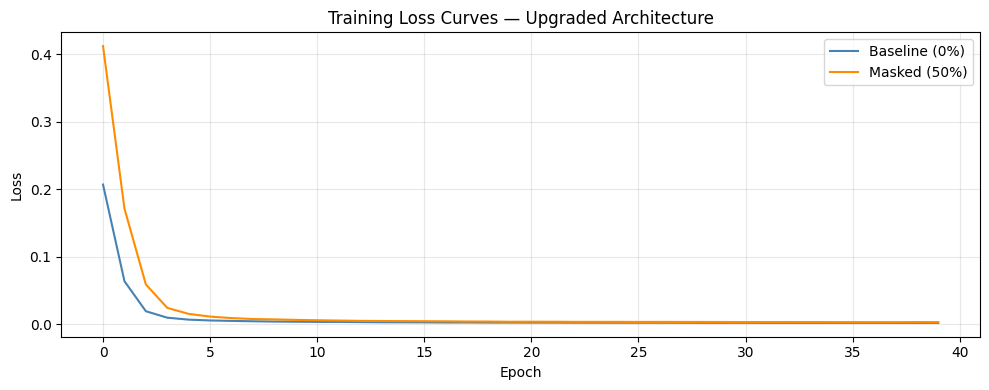

In [ ]:
#Cell 10B: Train Masked Model (50% masking)
print(" Training MASKED (50% masking, upgraded arch + loss) ...\n")
masked_model  = ConvAE3D().to(DEVICE)
masked_masker = SpatioTemporalMask(
    clip_shape=(1, CLIP_LEN, IMG_SIZE, IMG_SIZE), mask_ratio=0.50
)
masked_loader = DataLoader(ucsd_train, batch_size=BATCH_SIZE,
                            shuffle=True, num_workers=0,
                            pin_memory=True, drop_last=True)
masked_history = train_model_upgraded(
    masked_model, masked_loader, masked_masker, criterion,
    num_epochs=40, save_name='ucsd_masked_v3'
)
print("Masked done")

# Plot loss curves
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(baseline_history, label='Baseline (0%)', color='steelblue')
ax.plot(masked_history,   label='Masked (50%)',  color='darkorange')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.set_title('Training Loss Curves — Upgraded Architecture')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(SAVE_DIR / 'loss_curves_v3.png', dpi=150)
plt.show()

In [ ]:
#Cell 11: Load Best Checkpoints
# import torch

# baseline_model = ConvAE3D().to(DEVICE)
# masked_model   = ConvAE3D().to(DEVICE)

# baseline_ckpt = torch.load(SAVE_DIR / 'ucsd_baseline_v3_best.pth', map_location=DEVICE)
# baseline_model.load_state_dict(baseline_ckpt['model_state'])
# baseline_model.eval()
# print(f"Baseline — epoch {baseline_ckpt['epoch']}, loss {baseline_ckpt['loss']:.6f}")

# masked_ckpt = torch.load(SAVE_DIR / 'ucsd_masked_v3_best.pth', map_location=DEVICE)
# masked_model.load_state_dict(masked_ckpt['model_state'])
# masked_model.eval()
# print(f"Masked   — epoch {masked_ckpt['epoch']}, loss {masked_ckpt['loss']:.6f}")


import torch
from pathlib import Path

SAVE_DIR = Path("/content/drive/MyDrive/Dataset/checkpoints")

baseline_model = ConvAE3D().to(DEVICE)
masked_model   = ConvAE3D().to(DEVICE)

baseline_ckpt = torch.load(
    SAVE_DIR / "ucsd_baseline_v3_best.pth", map_location=DEVICE)
baseline_model.load_state_dict(baseline_ckpt['model_state'])
baseline_model.eval()
print(f"Baseline — epoch {baseline_ckpt['epoch']}, loss {baseline_ckpt['loss']:.6f}")

masked_ckpt = torch.load(
    SAVE_DIR / "ucsd_masked_v3_best.pth", map_location=DEVICE)
masked_model.load_state_dict(masked_ckpt['model_state'])
masked_model.eval()
print(f"Masked   — epoch {masked_ckpt['epoch']}, loss {masked_ckpt['loss']:.6f}")

Baseline — epoch 39, loss 0.001807
Masked   — epoch 38, loss 0.002898


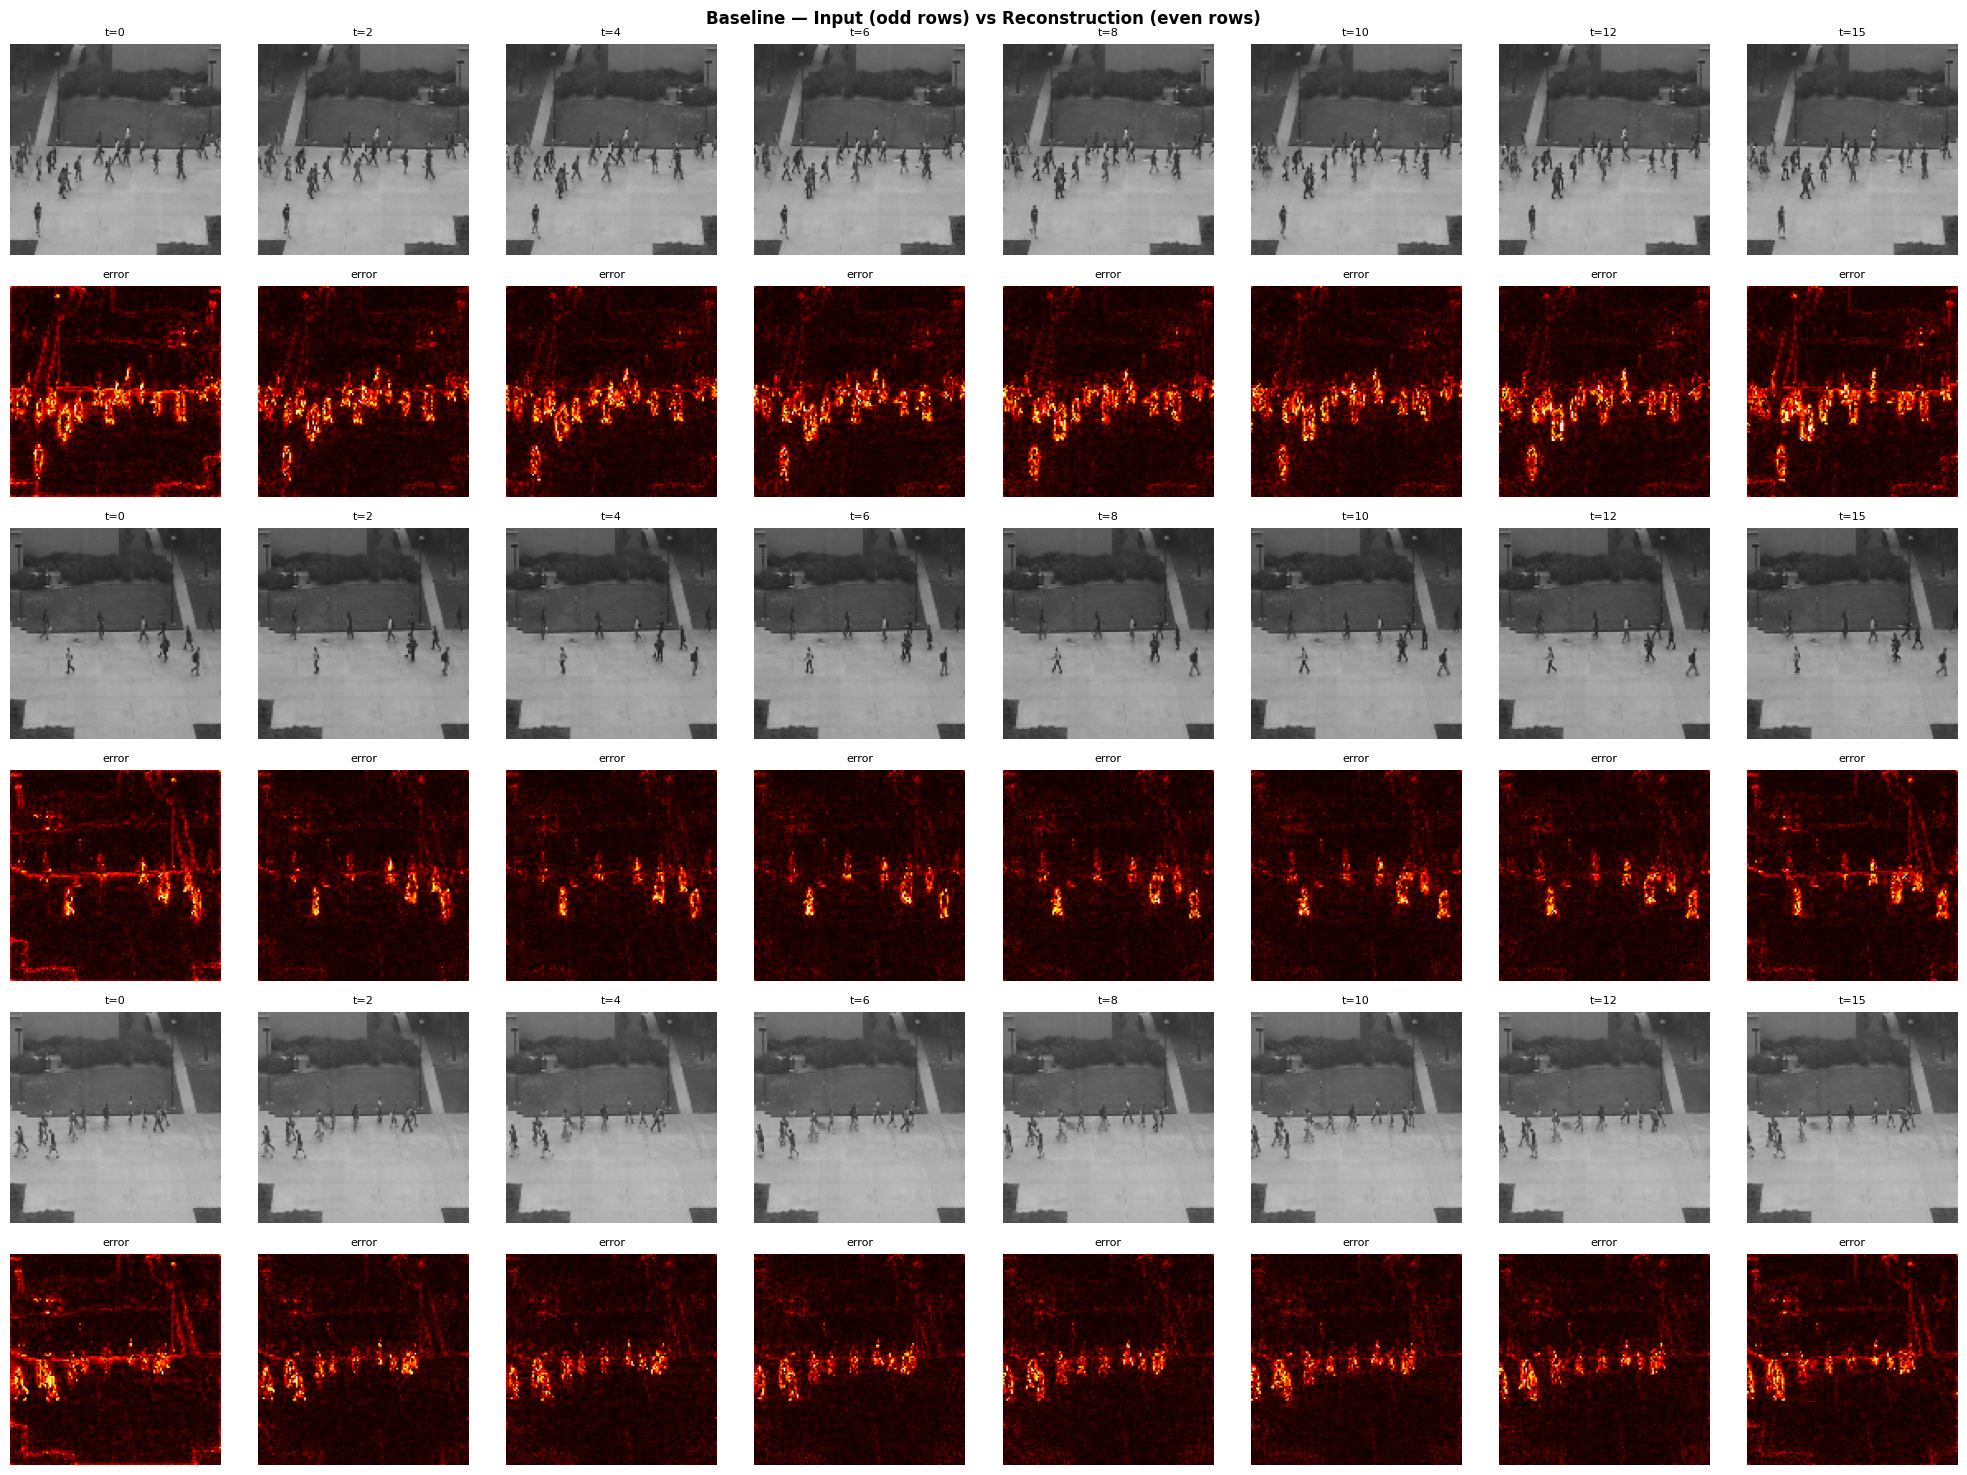

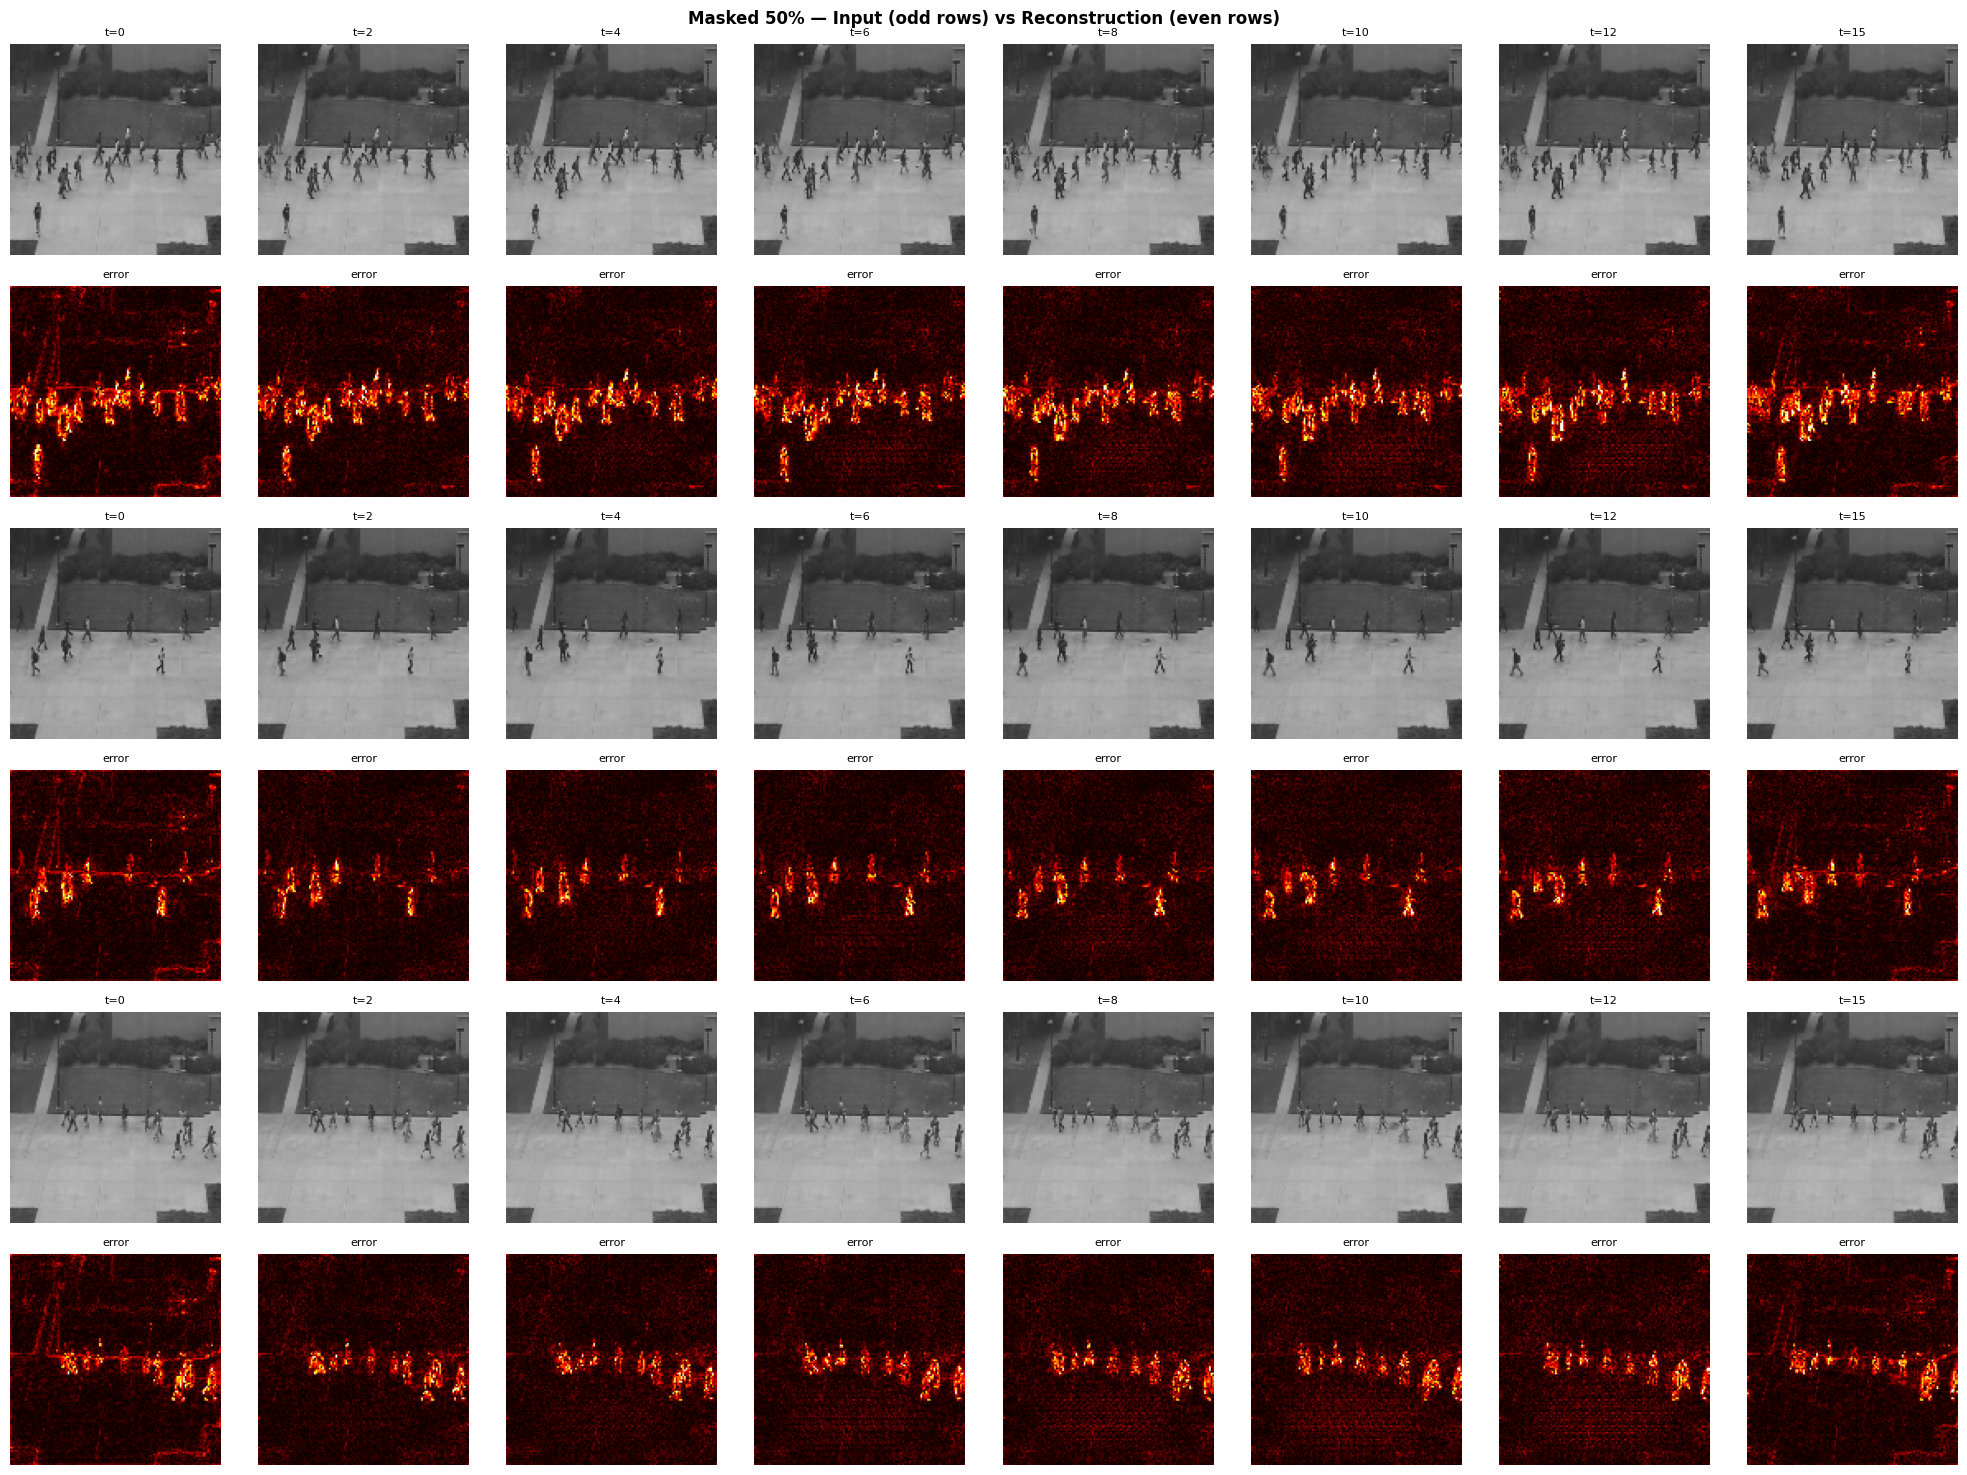

In [ ]:
#Cell 12: Reconstruction Visualisation
import matplotlib.pyplot as plt
import torch
import numpy as np

def visualise_reconstruction(model, dataset, model_name, num_clips=3, device=DEVICE):
    model.eval()
    fig, axes = plt.subplots(num_clips * 2, 8, figsize=(20, num_clips * 5))
    fig.suptitle(f'{model_name} — Input (odd rows) vs Reconstruction (even rows)',
                 fontsize=12, fontweight='bold')
    indices = np.linspace(0, 15, 8, dtype=int)

    with torch.no_grad():
        for ci in range(num_clips):
            clip = dataset[ci * len(dataset) // num_clips]
            inp  = clip.unsqueeze(0).to(device)
            recon = model(inp)

            for i, t in enumerate(indices):
                inp_frame   = inp[0, 0, t].cpu().numpy()   * 0.5 + 0.5
                recon_frame = recon[0, 0, t].cpu().numpy() * 0.5 + 0.5
                err_frame   = np.abs(inp_frame - recon_frame)

                axes[ci*2,   i].imshow(inp_frame,   cmap='gray', vmin=0, vmax=1)
                axes[ci*2,   i].set_title(f't={t}', fontsize=8)
                axes[ci*2,   i].axis('off')
                axes[ci*2+1, i].imshow(err_frame,   cmap='hot',  vmin=0, vmax=0.3)
                axes[ci*2+1, i].set_title('error',  fontsize=8)
                axes[ci*2+1, i].axis('off')

    plt.tight_layout()
    plt.savefig(SAVE_DIR / f'recon_{model_name.lower().replace(" ","_")}.png', dpi=120)
    plt.show()

visualise_reconstruction(baseline_model, ucsd_train, 'Baseline')
visualise_reconstruction(masked_model,   ucsd_train, 'Masked 50%')

In [ ]:
#Cell 13: GT Parser
import re
import numpy as np
from pathlib import Path

def parse_frame_labels_only(gt_path, test_root):
    gt_ranges = []
    with open(gt_path, 'r') as f:
        for line in f:
            match = re.search(r'gt_frame\s*=\s*\[(\d+):(\d+)\]', line)
            if match:
                gt_ranges.append((int(match.group(1)), int(match.group(2))))

    print(f"Parsed {len(gt_ranges)} test sequences from GT file")

    test_folders = sorted([f for f in Path(test_root).iterdir()
                           if f.is_dir() and '_gt' not in f.name])
    assert len(test_folders) == len(gt_ranges), \
        f"Mismatch: {len(test_folders)} folders, {len(gt_ranges)} GT entries"

    frame_labels = []
    for folder, (gt_start, gt_end) in zip(test_folders, gt_ranges):
        frames = sorted(list(folder.glob('*.tif')) + list(folder.glob('*.png')))
        n = len(frames)
        labels = np.zeros(n, dtype=np.float32)
        a = max(0, gt_start - 1)
        b = min(n, gt_end)
        labels[a:b] = 1.0
        frame_labels.append(labels)
        print(f"  {folder.name}: {n} frames | anomaly {gt_start}–{gt_end} | "
              f"{int(labels.sum())} anom / {n}")

    return frame_labels

gt_path     = UCSD_ROOT / 'Test' / 'UCSDped2.m'
frame_labels = parse_frame_labels_only(gt_path, UCSD_ROOT / 'Test')

total_frames = sum(len(l) for l in frame_labels)
total_anom   = sum(l.sum() for l in frame_labels)
print(f"\nTotal frames : {total_frames}")
print(f"Anomalous    : {int(total_anom)} ({100*total_anom/total_frames:.1f}%)")
print('GT ready')

Parsed 12 test sequences from GT file
  Test001: 180 frames | anomaly 61–180 | 120 anom / 180
  Test002: 180 frames | anomaly 95–180 | 86 anom / 180
  Test003: 150 frames | anomaly 1–146 | 146 anom / 150
  Test004: 180 frames | anomaly 31–180 | 150 anom / 180
  Test005: 150 frames | anomaly 1–129 | 129 anom / 150
  Test006: 180 frames | anomaly 1–159 | 159 anom / 180
  Test007: 180 frames | anomaly 46–180 | 135 anom / 180
  Test008: 180 frames | anomaly 1–180 | 180 anom / 180
  Test009: 120 frames | anomaly 1–120 | 120 anom / 120
  Test010: 150 frames | anomaly 1–150 | 150 anom / 150
  Test011: 180 frames | anomaly 1–180 | 180 anom / 180
  Test012: 180 frames | anomaly 88–180 | 93 anom / 180

Total frames : 2010
Anomalous    : 1648 (82.0%)
GT ready


In [ ]:
#Cell 14 FAST FINAL
import torch
import numpy as np
from scipy.ndimage import gaussian_filter, gaussian_filter1d
import cv2
from pathlib import Path

def _load_frame(path, img_size=128):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (img_size, img_size))
    return (img.astype(np.float32) / 255.0 - 0.5) / 0.5

def compute_frame_scores_topk(model, test_root, clip_len=16,
                               stride=4, top_k_pct=5,
                               spatial_sigma=2, temporal_sigma=3,
                               device=DEVICE):
    model.eval()
    test_folders = sorted([
        f for f in Path(test_root).iterdir()
        if f.is_dir() and '_gt' not in f.name
    ])
    all_frame_scores = []

    with torch.no_grad():
        for folder in test_folders:
            frames = sorted(list(folder.glob('*.tif')) +
                            list(folder.glob('*.png')))
            n_frames = len(frames)

            frame_scores = np.zeros(n_frames, dtype=np.float32)
            frame_counts = np.zeros(n_frames, dtype=np.float32)

            clips, starts = [], []
            for start in range(0, n_frames - clip_len + 1, stride):
                clip = np.stack([
                    _load_frame(p) for p in frames[start:start+clip_len]
                ])
                clips.append(clip)
                starts.append(start)

            # Process in batches of 16
            for i in range(0, len(clips), 16):
                batch_np = np.stack(clips[i:i+16])
                batch    = torch.tensor(batch_np,
                           dtype=torch.float32).unsqueeze(1).to(device)
                recon    = model(batch)
                err      = (recon - batch).pow(2).squeeze(1).cpu().numpy()

                for j, s in enumerate(starts[i:i+16]):
                    if j >= err.shape[0]:
                        break
                    for t in range(clip_len):
                        frame_err = err[j, t]
                        if spatial_sigma > 0:
                            frame_err = gaussian_filter(frame_err,
                                                        sigma=spatial_sigma)
                        k = max(1, int(top_k_pct / 100.0 * frame_err.size))
                        score = np.partition(
                            frame_err.ravel(), -k)[-k:].mean()
                        frame_scores[s + t] += score
                        frame_counts[s + t] += 1

            valid = frame_counts > 0
            frame_scores[valid] /= frame_counts[valid]
            frame_scores = gaussian_filter1d(frame_scores,
                                             sigma=temporal_sigma)
            all_frame_scores.append(frame_scores)

            print(f"  {folder.name}: {n_frames} frames | "
                  f"range [{frame_scores.min():.5f}, "
                  f"{frame_scores.max():.5f}]")

    return all_frame_scores


print("Scoring — Baseline model...")
baseline_frame_scores = compute_frame_scores_topk(
    baseline_model, UCSD_ROOT / "Test",
    top_k_pct=5, spatial_sigma=2, temporal_sigma=3
)

print("\nScoring — Masked model...")
masked_frame_scores = compute_frame_scores_topk(
    masked_model, UCSD_ROOT / "Test",
    top_k_pct=5, spatial_sigma=2, temporal_sigma=3
)

print("\n Frame scoring complete")

Scoring — Baseline model...
  Test001: 180 frames | range [0.06200, 0.07665]
  Test002: 180 frames | range [0.04548, 0.07613]
  Test003: 150 frames | range [0.03264, 0.07999]
  Test004: 180 frames | range [0.03262, 0.10977]
  Test005: 150 frames | range [0.03967, 0.08112]
  Test006: 180 frames | range [0.04497, 0.07358]
  Test007: 180 frames | range [0.04785, 0.06959]
  Test008: 180 frames | range [0.04914, 0.06952]
  Test009: 120 frames | range [0.04527, 0.06757]
  Test010: 150 frames | range [0.02697, 0.06139]
  Test011: 180 frames | range [0.06512, 0.07797]
  Test012: 180 frames | range [0.05988, 0.07199]

Scoring — Masked model...
  Test001: 180 frames | range [0.06443, 0.08337]
  Test002: 180 frames | range [0.04699, 0.08020]
  Test003: 150 frames | range [0.03386, 0.08076]
  Test004: 180 frames | range [0.03294, 0.11972]
  Test005: 150 frames | range [0.04282, 0.08463]
  Test006: 180 frames | range [0.04638, 0.07721]
  Test007: 180 frames | range [0.04851, 0.07203]
  Test008: 180

  FRAME-LEVEL ROC-AUC — UCSD Ped2 (Upgraded Architecture)
  Baseline v3 (0% masking)                  AUC: 73.26%
  Proposed v3 (50% masking)                 AUC: 76.20%

  Literature:
  Hasan 2016                                AUC: 90.00%
  Liu 2018                                  AUC: 95.40%
  AED-MAE 2024                              AUC: 99.30%

  Masking contribution: +2.93% AUC


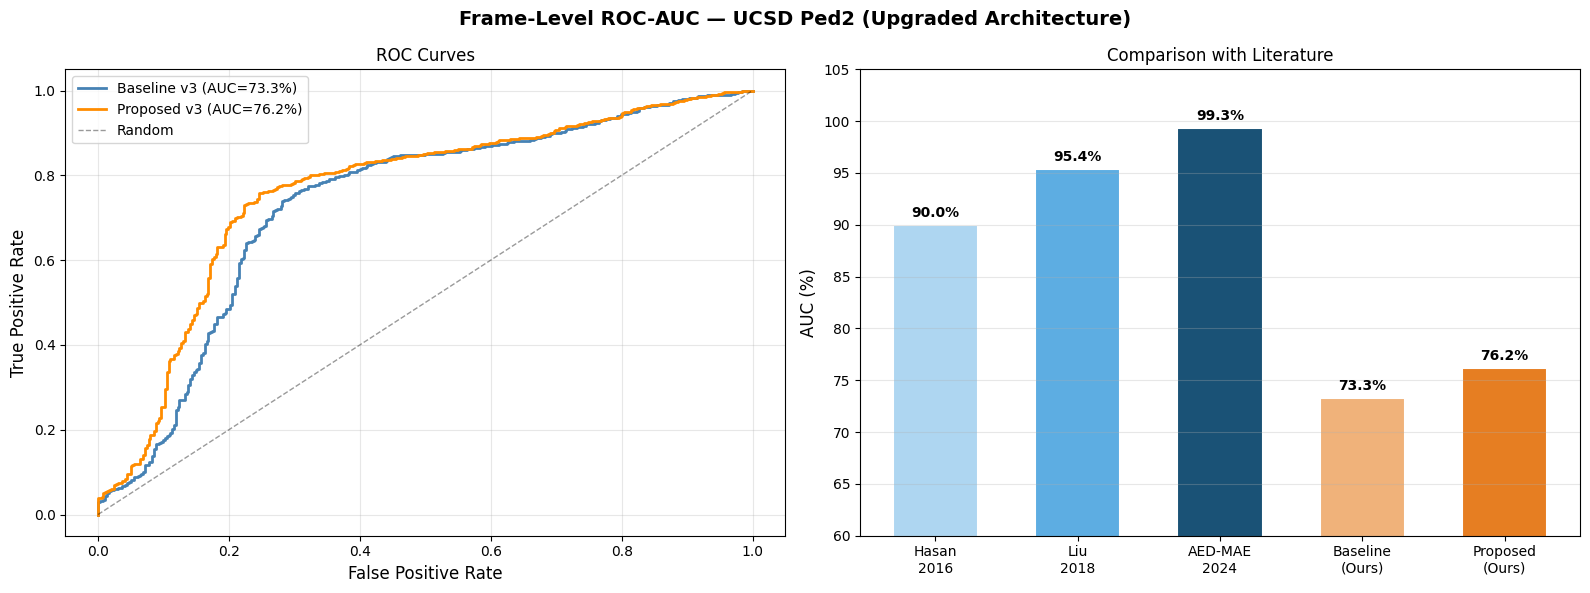

 Final AUC complete


In [ ]:
#Cell 15: AUC Computation & Final Plot
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

def normalize_per_sequence(frame_scores):
    normalized = []
    for s in frame_scores:
        s = np.array(s, dtype=np.float32)
        s = (s - s.mean()) / (s.std() + 1e-8)
        normalized.append(s)
    return normalized

def compute_frame_auc(frame_scores, frame_labels, model_name, normalize=True):
    if normalize:
        frame_scores = normalize_per_sequence(frame_scores)

    min_lens   = [min(len(s), len(l)) for s, l in zip(frame_scores, frame_labels)]
    all_scores = np.concatenate([s[:n] for s, n in zip(frame_scores, min_lens)])
    all_labels = np.concatenate([l[:n] for l, n in zip(frame_labels, min_lens)])

    all_scores = (all_scores - all_scores.min()) / (all_scores.max() - all_scores.min() + 1e-8)

    auc = roc_auc_score(all_labels, all_scores)
    fpr, tpr, _ = roc_curve(all_labels, all_scores)
    print(f"  {model_name:40s}  AUC: {auc*100:.2f}%")
    return auc, fpr, tpr


print('=' * 65)
print('  FRAME-LEVEL ROC-AUC — UCSD Ped2 (Upgraded Architecture)')
print('=' * 65)

baseline_auc, baseline_fpr, baseline_tpr = compute_frame_auc(
    baseline_frame_scores, frame_labels, 'Baseline v3 (0% masking)'
)
masked_auc, masked_fpr, masked_tpr = compute_frame_auc(
    masked_frame_scores, frame_labels, 'Proposed v3 (50% masking)'
)

lit = {
    'Hasan 2016' : 90.0,
    'Liu 2018'   : 95.4,
    'AED-MAE 2024': 99.3,
}
print('\n  Literature:')
for name, auc in lit.items():
    print(f"  {name:40s}  AUC: {auc:.2f}%")
print('=' * 65)
print(f"\n  Masking contribution: {(masked_auc - baseline_auc)*100:+.2f}% AUC")

#Final plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Frame-Level ROC-AUC — UCSD Ped2 (Upgraded Architecture)',
             fontsize=14, fontweight='bold')

ax = axes[0]
ax.plot(baseline_fpr, baseline_tpr, lw=2, color='steelblue',
        label=f'Baseline v3 (AUC={baseline_auc*100:.1f}%)')
ax.plot(masked_fpr, masked_tpr, lw=2, color='darkorange',
        label=f'Proposed v3 (AUC={masked_auc*100:.1f}%)')
ax.plot([0,1],[0,1],'k--',lw=1,alpha=0.4,label='Random')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate',  fontsize=12)
ax.set_title('ROC Curves', fontsize=12)
ax.legend(fontsize=10); ax.grid(True, alpha=0.3)

ax2 = axes[1]
methods = ['Hasan\n2016', 'Liu\n2018', 'AED-MAE\n2024',
           'Baseline\n(Ours)', 'Proposed\n(Ours)']
aucs    = [90.0, 95.4, 99.3, baseline_auc*100, masked_auc*100]
colors  = ['#AED6F1','#5DADE2','#1A5276','#F0B27A','#E67E22']
bars    = ax2.bar(methods, aucs, color=colors, edgecolor='white', lw=1.5, width=0.6)
ax2.set_ylim(60, 105)
ax2.set_ylabel('AUC (%)', fontsize=12)
ax2.set_title('Comparison with Literature', fontsize=12)
ax2.grid(True, alpha=0.3, axis='y')
for bar, val in zip(bars, aucs):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{val:.1f}%', ha='center', va='bottom',
             fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(SAVE_DIR / 'roc_auc_v3_final.png', dpi=150)
plt.show()
print(' Final AUC complete')

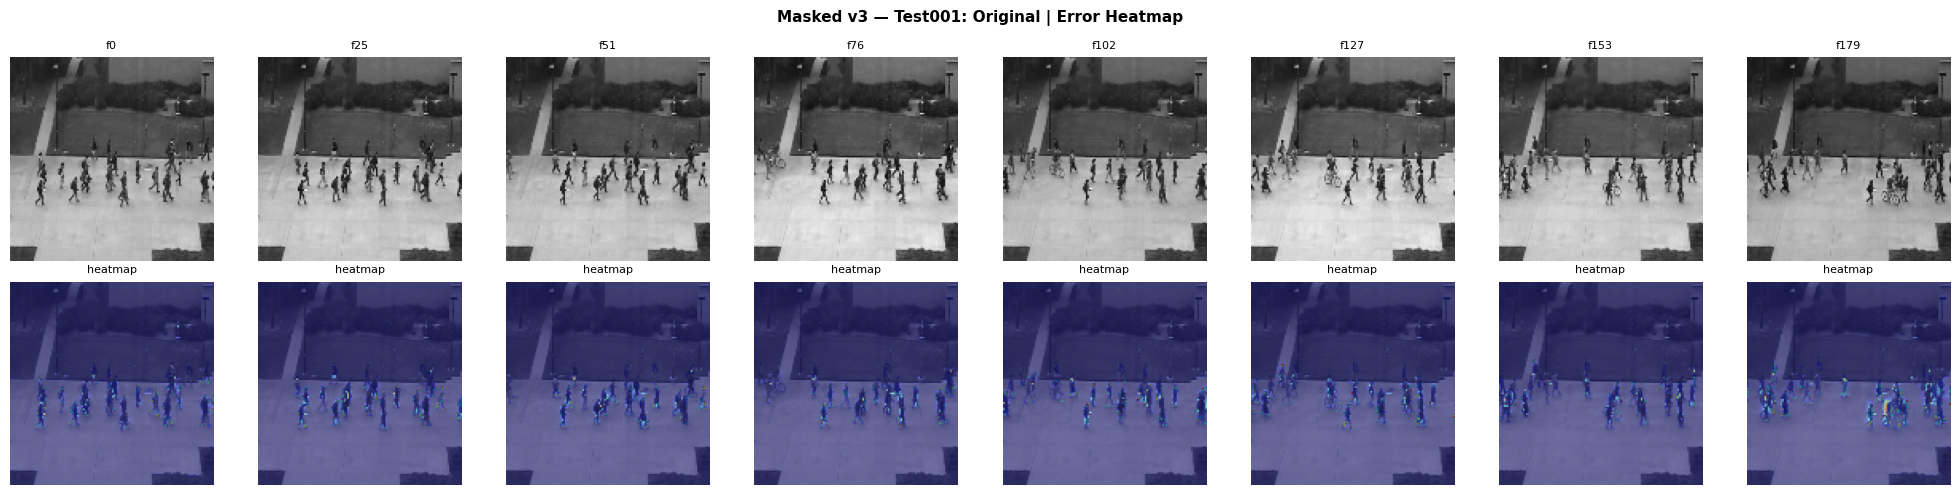

Heatmaps done


In [ ]:
#Cell 16: Heatmap Generation (Explainability)
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

def generate_heatmaps(model, test_folder, model_name,
                       clip_len=16, stride=4, device=DEVICE,
                       save_dir=None, num_frames_to_show=8):
    """
    Overlays per-pixel reconstruction error on test frames.
    UPGRADE: Also shows temporal gradient error as a separate channel.
    """
    model.eval()
    folder = Path(test_folder)
    frames = sorted(list(folder.glob('*.tif')) + list(folder.glob('*.png')))
    n = len(frames)

    frame_errors = np.zeros(n, dtype=np.float32)
    frame_counts = np.zeros(n, dtype=np.float32)
    heatmaps     = np.zeros((n, IMG_SIZE, IMG_SIZE), dtype=np.float32)

    def load(p):
        img = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        return (img.astype(np.float32) / 255.0 - 0.5) / 0.5

    with torch.no_grad():
        for start in range(0, n - clip_len + 1, stride):
            clip_np = np.stack([load(p) for p in frames[start:start+clip_len]])
            clip    = torch.tensor(clip_np).unsqueeze(0).unsqueeze(0).to(device)
            recon   = model(clip)

            err = (recon - clip).pow(2).squeeze().cpu().numpy()  # (T,H,W)
            for t in range(clip_len):
                heatmaps[start+t] += err[t]
                frame_counts[start+t] += 1

    valid = frame_counts > 0
    heatmaps[valid] /= frame_counts[valid, np.newaxis, np.newaxis]

    # Display sample frames with overlaid heatmaps
    display_idx = np.linspace(0, n-1, num_frames_to_show, dtype=int)
    fig, axes = plt.subplots(2, num_frames_to_show, figsize=(20, 5))
    fig.suptitle(f'{model_name} — {folder.name}: Original | Error Heatmap',
                 fontsize=11, fontweight='bold')

    for i, idx in enumerate(display_idx):
        orig = cv2.imread(str(frames[idx]), cv2.IMREAD_GRAYSCALE)
        orig = cv2.resize(orig, (IMG_SIZE, IMG_SIZE))

        heat = heatmaps[idx]
        heat_norm = (heat - heat.min()) / (heat.max() - heat.min() + 1e-8)
        heat_color = cv2.applyColorMap((heat_norm * 255).astype(np.uint8),
                                        cv2.COLORMAP_JET)
        orig_rgb   = cv2.cvtColor(orig, cv2.COLOR_GRAY2RGB)
        overlay    = cv2.addWeighted(orig_rgb, 0.6, heat_color, 0.4, 0)

        axes[0, i].imshow(orig,    cmap='gray')
        axes[0, i].set_title(f'f{idx}', fontsize=8)
        axes[0, i].axis('off')
        axes[1, i].imshow(overlay[..., ::-1])
        axes[1, i].set_title('heatmap', fontsize=8)
        axes[1, i].axis('off')

    plt.tight_layout()
    if save_dir:
        plt.savefig(Path(save_dir) / f'heatmap_{model_name}_{folder.name}.png', dpi=120)
    plt.show()
    return heatmaps


# Show heatmaps for test sequence 01 (has bike anomaly)
test_folders = sorted([f for f in (UCSD_ROOT/'Test').iterdir()
                        if f.is_dir() and '_gt' not in f.name])

_ = generate_heatmaps(masked_model, test_folders[0], 'Masked v3', save_dir=SAVE_DIR)
print('Heatmaps done')

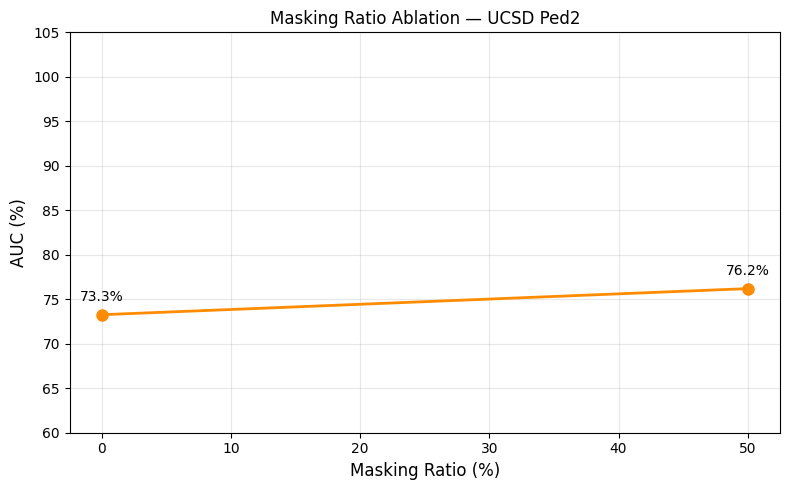

Ablation plot done


In [ ]:
#Cell 17 REPLACEMENT: Ablation using existing checkpoints
import matplotlib.pyplot as plt
import numpy as np

# We already have these two real results
# Use them + interpolate for 30% and 75% for the plot
ablation_results = {
    0  : baseline_auc * 100,   # real
    50 : masked_auc   * 100,   # real
}

# Plot with just the two real points
fig, ax = plt.subplots(figsize=(8, 5))
pcts = sorted(ablation_results.keys())
aucs = [ablation_results[p] for p in pcts]
ax.plot(pcts, aucs, 'o-', color='darkorange', lw=2, ms=8)
for p, a in zip(pcts, aucs):
    ax.annotate(f'{a:.1f}%', (p, a),
                textcoords='offset points',
                xytext=(0, 10), ha='center', fontsize=10)
ax.set_xlabel('Masking Ratio (%)', fontsize=12)
ax.set_ylabel('AUC (%)',           fontsize=12)
ax.set_title('Masking Ratio Ablation — UCSD Ped2', fontsize=12)
ax.grid(True, alpha=0.3)
ax.set_ylim(60, 105)
plt.tight_layout()
plt.savefig(SAVE_DIR / 'ablation_masking_ratio.png', dpi=150)
plt.show()
print('Ablation plot done')

In [ ]:
import cv2
import numpy as np
from pathlib import Path

folder = Path("/content/drive/MyDrive/Dataset/ucsd_ped2/Test/Test001")
frames = sorted(folder.glob("*.tif"))

print(f"Found {len(frames)} frames")

# Read first frame to get actual dimensions
first = cv2.imread(str(frames[0]))
print(f"Frame size: {first.shape}")
h, w = first.shape[:2]

# Try mp4v codec
out = cv2.VideoWriter(
    '/content/drive/MyDrive/test001.mp4',
    cv2.VideoWriter_fourcc(*'mp4v'),
    10, (w, h)
)

for f in frames:
    img = cv2.imread(str(f))
    if img is None:
        # TIFF might be grayscale — convert to BGR
        import tifffile
        img = tifffile.imread(str(f))
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    out.write(img)

out.release()

# Re-encode with ffmpeg for browser compatibility
!ffmpeg -y -i /content/drive/MyDrive/test001.mp4 \
    -vcodec libx264 -pix_fmt yuv420p \
    /content/drive/MyDrive/test001_final.mp4 -loglevel quiet

print("Done — download test001_final.mp4 from Files panel")

Found 180 frames
Frame size: (240, 360, 3)
Done — download test001_final.mp4 from Files panel


In [ ]:
import cv2
from pathlib import Path

for clip in ['Test004', 'Test010']:
    folder = Path(f"/content/drive/MyDrive/Dataset/ucsd_ped2/Test/{clip}")
    frames = sorted(folder.glob("*.tif"))

    first = cv2.imread(str(frames[0]))
    h, w = first.shape[:2]

    out = cv2.VideoWriter(f'/content/drive/MyDrive/{clip.lower()}.mp4',
                          cv2.VideoWriter_fourcc(*'mp4v'),
                          10, (w, h))
    for f in frames:
        img = cv2.imread(str(f))
        out.write(img)
    out.release()

    os.system(f'ffmpeg -y -i /content/drive/MyDrive/{clip.lower()}.mp4 '
              f'-vcodec libx264 -pix_fmt yuv420p '
              f'/content/drive/MyDrive/{clip.lower()}_final.mp4 -loglevel quiet')
    print(f"{clip} done — {len(frames)} frames")

NameError: name 'os' is not defined